<a href="https://colab.research.google.com/github/srabani-khuntia/Machine-Learning-Lab/blob/main/Assignment-7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ASSIGNMENT - 7: Forward Stepwise Feature Selection & Model Evaluation**



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.svm import LinearSVC, SVC, LinearSVR, SVR
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

##### **1. Implement Forward Stepwise selection approach to select the features for your dataset.**

For classification dataset:

In [ ]:
# Loading the classification dataset
from google.colab import files

uploaded = files.upload()
campus_df = pd.read_csv('campus_preprocessed.csv')

print("Dataset loaded successfully!")

Saving campus_preprocessed.csv to campus_preprocessed.csv
Dataset loaded successfully!


In [ ]:
# Separate Features and Target
X_class = campus_df.drop('placed', axis=1)
y_class = campus_df['placed']

print("Feature Shape:", X_class.shape)
print("Target Shape:", y_class.shape)

Feature Shape: (100000, 33)
Target Shape: (100000,)


In [ ]:
# Train-Test Split
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

print("Training Dataset Shape:", X_train_class.shape)
print("Testing Dataset Shape:", X_test_class.shape)

Training Dataset Shape: (80000, 33)
Testing Dataset Shape: (20000, 33)


In [ ]:
# Create a sample for feature selection
X_fs_class, _, y_fs_class, _ = train_test_split(
    X_train_class,
    y_train_class,
    train_size=min(5000, len(X_train_class)),
    random_state=42,
    stratify=y_train_class
)

# Create the estimator
fs_classifier = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Apply Forward Stepwise Selection
forward_selector_class = SequentialFeatureSelector(
    estimator=fs_classifier,
    n_features_to_select=10,
    direction='forward',
    scoring='accuracy',
    cv=3,
    n_jobs=-1
)

forward_selector_class.fit(X_fs_class, y_fs_class)

# Obtain selected features
selected_features_class = X_train_class.columns[
    forward_selector_class.get_support()
].tolist()

print("Selected Classification Features:")
print(selected_features_class)

print("\nNumber of Selected Features:",
      len(selected_features_class))

Selected Classification Features:
['age', 'degree_percentage', 'internships_count', 'certifications_count', 'soft_skills_score', 'work_experience_months', 'extracurricular_activities', 'backlogs', 'gender_Other', 'degree_field_Business']

Number of Selected Features: 10


In [ ]:
X_train_class_selected = X_train_class[selected_features_class]
X_test_class_selected = X_test_class[selected_features_class]

print("Training Dataset Shape After Feature Selection:",
      X_train_class_selected.shape)

print("Testing Dataset Shape After Feature Selection:",
      X_test_class_selected.shape)

Training Dataset Shape After Feature Selection: (80000, 10)
Testing Dataset Shape After Feature Selection: (20000, 10)


For regression dataset:

In [ ]:
# Loading the classification dataset
from google.colab import files

uploaded = files.upload()
uber_df = pd.read_csv('uber_preprocessed.csv')

print("Dataset loaded successfully!")

Saving uber_preprocessed.csv to uber_preprocessed.csv
Dataset loaded successfully!


In [ ]:
# Separate Features and Target
X_reg = uber_df.drop('fare_amount', axis=1)
y_reg = uber_df['fare_amount']

print("Feature Shape:", X_reg.shape)
print("Target Shape:", y_reg.shape)

Feature Shape: (194918, 10)
Target Shape: (194918,)


In [ ]:
# Train-Test Split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Training Dataset Shape:", X_train_reg.shape)
print("Testing Dataset Shape:", X_test_reg.shape)

Training Dataset Shape: (155934, 10)
Testing Dataset Shape: (38984, 10)


In [ ]:
# Create a sample for feature selection
X_fs_reg = X_train_reg.sample(
    n=min(20000, len(X_train_reg)),
    random_state=42
)

y_fs_reg = y_train_reg.loc[X_fs_reg.index]

# Create the estimator
fs_regressor = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

# Apply Forward Stepwise Selection
forward_selector_reg = SequentialFeatureSelector(
    estimator=fs_regressor,
    n_features_to_select=5,
    direction='forward',
    scoring='r2',
    cv=3,
    n_jobs=-1
)

forward_selector_reg.fit(X_fs_reg, y_fs_reg)

# Obtain selected features
selected_features_reg = X_train_reg.columns[
    forward_selector_reg.get_support()
].tolist()

print("Selected Regression Features:")
print(selected_features_reg)

print("\nNumber of Selected Features:",
      len(selected_features_reg))

Selected Regression Features:
['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'pickup_year']

Number of Selected Features: 5


In [ ]:
# Create Selected Feature Datasets
X_train_reg_selected = X_train_reg[selected_features_reg]
X_test_reg_selected = X_test_reg[selected_features_reg]

print("Training Dataset Shape After Feature Selection:",
      X_train_reg_selected.shape)

print("Testing Dataset Shape After Feature Selection:",
      X_test_reg_selected.shape)

Training Dataset Shape After Feature Selection: (155934, 5)
Testing Dataset Shape After Feature Selection: (38984, 5)


##### **2.After feature selection, implement classification ML models. (KNN, Logistic regression, Naïve bay’s, decision tree, random forest, SVM, KSVM, LDA)**

In [ ]:
# Define Classification Models
classification_models = {
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5, n_jobs=-1))
    ]),

    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ]),

    'Naive Bayes': Pipeline([
        ('scaler', StandardScaler()),
        ('model', GaussianNB())
    ]),

    'Decision Tree': DecisionTreeClassifier(random_state=42),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    'SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearSVC(max_iter=5000, random_state=42))
    ]),

    'KSVM': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', random_state=42))
    ]),

    'LDA': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearDiscriminantAnalysis())
    ])
}

In [ ]:
# Train Classification Models
classification_results = {}

# Prepare a sample for KSVM
X_ksvm = X_train_class_selected.sample(
    n=min(5000, len(X_train_class_selected)),
    random_state=42
)

y_ksvm = y_train_class.loc[X_ksvm.index]

for model_name, model in classification_models.items():

    print("Training:", model_name)

    if model_name == 'KSVM':
        model.fit(X_ksvm, y_ksvm)
    else:
        model.fit(X_train_class_selected, y_train_class)

    classification_results[model_name] = model

print("\nAll Classification Models Trained Successfully.")

Training: KNN
Training: Logistic Regression
Training: Naive Bayes
Training: Decision Tree
Training: Random Forest
Training: SVM
Training: KSVM
Training: LDA

All Classification Models Trained Successfully.


##### **3.Calculate the performances such as Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve for classification.**

In [ ]:
# Calculate Performance Metrics

classification_metrics = {}

for model_name, model in classification_results.items():

    y_pred = model.predict(X_test_class_selected)

    # Obtain prediction scores for ROC curve
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test_class_selected)[:, 1]
    else:
        y_score = model.decision_function(X_test_class_selected)

    cm = confusion_matrix(y_test_class, y_pred)

    accuracy = accuracy_score(y_test_class, y_pred)
    precision = precision_score(y_test_class, y_pred)
    recall = recall_score(y_test_class, y_pred)
    f1 = f1_score(y_test_class, y_pred)
    auc = roc_auc_score(y_test_class, y_score)

    classification_metrics[model_name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUC': auc,
        'Confusion Matrix': cm
    }

    print("\nModel:", model_name)
    print("\nConfusion Matrix:\n", cm)
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1-Score:", f1)
    print("ROC-AUC Score:", auc)


Model: KNN

Confusion Matrix:
 [[  784  2330]
 [  857 16029]]
Accuracy: 0.84065
Precision: 0.8730867694318862
Recall: 0.9492478976667061
F1-Score: 0.9095758263583487
ROC-AUC Score: 0.7247247894015336

Model: Logistic Regression

Confusion Matrix:
 [[  672  2442]
 [  451 16435]]
Accuracy: 0.85535
Precision: 0.8706362239762674
Recall: 0.9732914840696435
F1-Score: 0.9191063389536672
ROC-AUC Score: 0.8230162354360737

Model: Naive Bayes

Confusion Matrix:
 [[  745  2369]
 [  692 16194]]
Accuracy: 0.84695
Precision: 0.8723805419382643
Recall: 0.9590193059339097
F1-Score: 0.9136505966317808
ROC-AUC Score: 0.8079220426432845

Model: Decision Tree

Confusion Matrix:
 [[ 1055  2059]
 [ 2367 14519]]
Accuracy: 0.7787
Precision: 0.8757992520207504
Recall: 0.859824706857752
F1-Score: 0.8677384652163519
ROC-AUC Score: 0.5992961432937532

Model: Random Forest

Confusion Matrix:
 [[  718  2396]
 [  579 16307]]
Accuracy: 0.85125
Precision: 0.8718922098059135
Recall: 0.9657112400805401
F1-Score: 0.9164

In [ ]:
# Classification Performance Comparison Table

classification_comparison = pd.DataFrame({
    model: {
        metric: values[metric]
        for metric in ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC']
    }
    for model, values in classification_metrics.items()
}).T

classification_comparison

,Accuracy,Precision,Recall,F1-Score,AUC
KNN,0.84065,0.873087,0.949248,0.909576,0.724725
Logistic Regression,0.85535,0.870636,0.973291,0.919106,0.823016
Naive Bayes,0.84695,0.872381,0.959019,0.913651,0.807922
Decision Tree,0.77870,0.875799,0.859825,0.867738,0.599296
Random Forest,0.85125,0.871892,0.965711,0.916407,0.800148
SVM,0.85605,0.862744,0.986438,0.920454,0.822929
KSVM,0.85215,0.855205,0.993012,0.918971,0.711167
LDA,0.85355,0.872604,0.967843,0.917759,0.821073


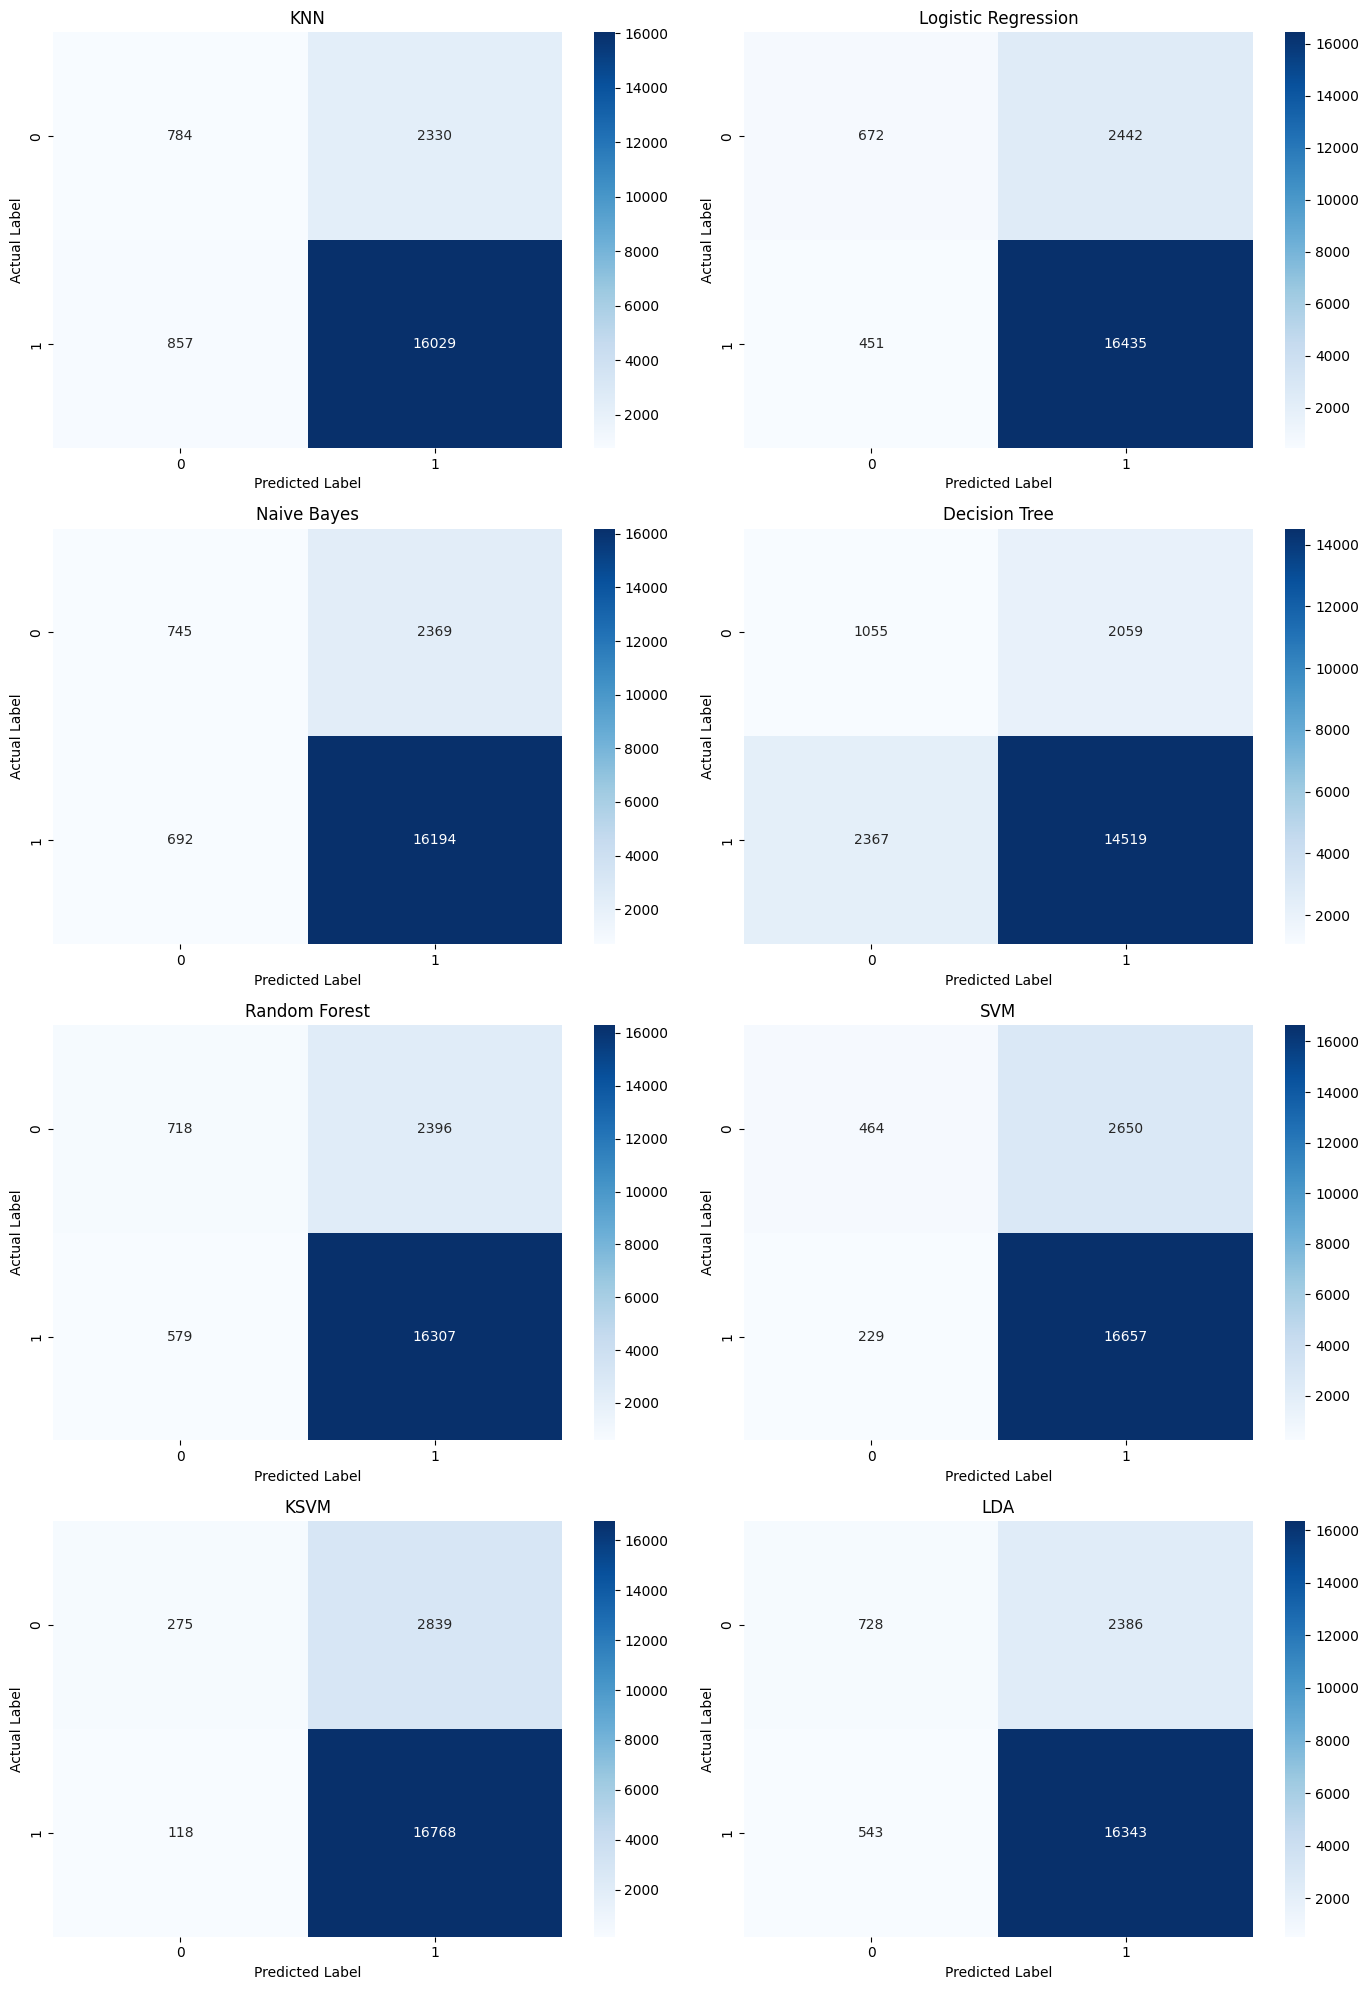

In [ ]:
# Confusion Matrices
fig, axes = plt.subplots(4, 2, figsize=(14, 20))

for ax, (model_name, values) in zip(
    axes.flatten(),
    classification_metrics.items()
):
    sns.heatmap(
        values['Confusion Matrix'],
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

In [ ]:
# Classification Reports
for model_name, model in classification_results.items():

    y_pred = model.predict(X_test_class_selected)

    print("\nClassification Report:", model_name)
    print(classification_report(y_test_class, y_pred))


Classification Report: KNN
              precision    recall  f1-score   support

           0       0.48      0.25      0.33      3114
           1       0.87      0.95      0.91     16886

    accuracy                           0.84     20000
   macro avg       0.68      0.60      0.62     20000
weighted avg       0.81      0.84      0.82     20000


Classification Report: Logistic Regression
              precision    recall  f1-score   support

           0       0.60      0.22      0.32      3114
           1       0.87      0.97      0.92     16886

    accuracy                           0.86     20000
   macro avg       0.73      0.59      0.62     20000
weighted avg       0.83      0.86      0.83     20000


Classification Report: Naive Bayes
              precision    recall  f1-score   support

           0       0.52      0.24      0.33      3114
           1       0.87      0.96      0.91     16886

    accuracy                           0.85     20000
   macro avg       0

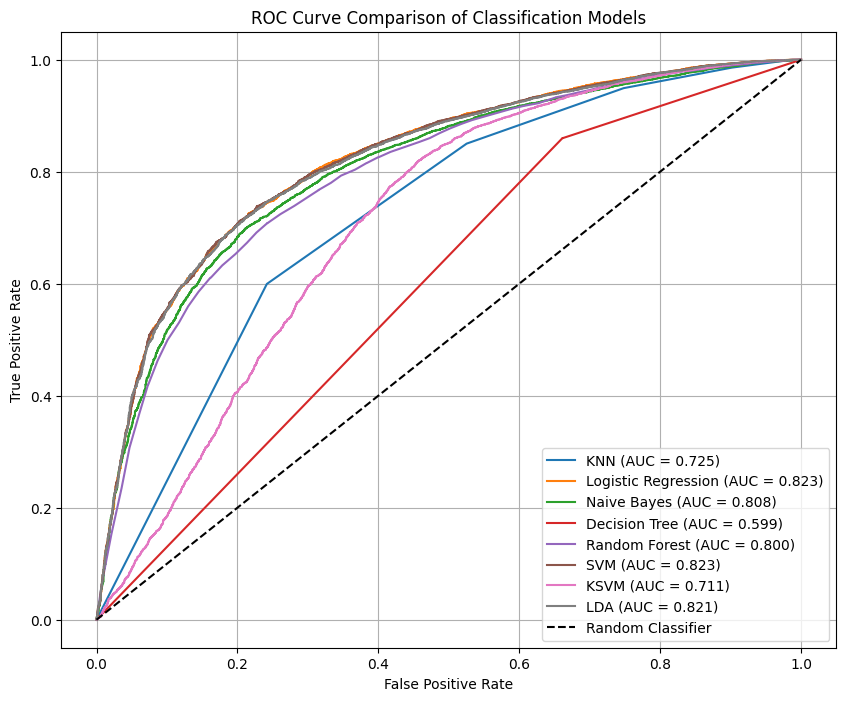

In [ ]:
# ROC Curve
plt.figure(figsize=(10, 8))

for model_name, model in classification_results.items():

    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test_class_selected)[:, 1]
    else:
        y_score = model.decision_function(X_test_class_selected)

    fpr, tpr, thresholds = roc_curve(y_test_class, y_score)

    auc = roc_auc_score(y_test_class, y_score)

    plt.plot(
        fpr,
        tpr,
        label=f'{model_name} (AUC = {auc:.3f})'
    )

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison of Classification Models')
plt.legend()
plt.grid()
plt.show()

##### **4.After feature selection, implement regression ML models. (KNN, multiple linear regression, SVM, KSVM, decision tree, random forest)**

In [ ]:
# Define Regression Models

regression_models = {
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=5, n_jobs=-1))
    ]),

    'Multiple Linear Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),

    'SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearSVR(max_iter=5000, random_state=42))
    ]),

    'KSVM': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVR(kernel='rbf'))
    ]),

    'Decision Tree': DecisionTreeRegressor(random_state=42),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

In [ ]:
# Train Regression Models
regression_results = {}

# Prepare a sample for KSVM
X_ksvm_reg = X_train_reg_selected.sample(
    n=min(5000, len(X_train_reg_selected)),
    random_state=42
)

y_ksvm_reg = y_train_reg.loc[X_ksvm_reg.index]

for model_name, model in regression_models.items():

    print("Training:", model_name)

    if model_name == 'KSVM':
        model.fit(X_ksvm_reg, y_ksvm_reg)
    else:
        model.fit(X_train_reg_selected, y_train_reg)

    regression_results[model_name] = model

print("\nAll Regression Models Trained Successfully.")

Training: KNN
Training: Multiple Linear Regression
Training: SVM
Training: KSVM
Training: Decision Tree
Training: Random Forest

All Regression Models Trained Successfully.


##### **5.Calculate the performances such as MAE, MSE, RMSE, and R2 for regression.**

In [ ]:
# Calculate Regression Metrics

regression_metrics = {}

for model_name, model in regression_results.items():

    y_pred = model.predict(X_test_reg_selected)

    mae = mean_absolute_error(y_test_reg, y_pred)
    mse = mean_squared_error(y_test_reg, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_reg, y_pred)

    regression_metrics[model_name] = {
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }

    print("\nModel:", model_name)
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R2 Score:", r2)


Model: KNN
MAE: 1.9818217730350913
MSE: 16.56205353457829
RMSE: 4.069650296349588
R2 Score: 0.8210852559976218

Model: Multiple Linear Regression
MAE: 5.0757581211346725
MSE: 65.23708805540963
RMSE: 8.076947941853385
R2 Score: 0.29526390646391454

Model: SVM
MAE: 4.854298626932927
MSE: 68.39555328637122
RMSE: 8.270160414790709
R2 Score: 0.26114398304632025

Model: KSVM
MAE: 2.3481914552330934
MSE: 22.91807433312136
RMSE: 4.787282562490057
R2 Score: 0.7524231283411142

Model: Decision Tree
MAE: 2.633057835693276
MSE: 30.15658406725266
RMSE: 5.4915010759584355
R2 Score: 0.6742277455441101

Model: Random Forest
MAE: 1.8973047966361456
MSE: 14.699693081283119
RMSE: 3.8340178770166315
R2 Score: 0.8412037602064021


In [ ]:
# Regression Performance Comparison Table
regression_comparison = pd.DataFrame(
    regression_metrics
).T

regression_comparison

,MAE,MSE,RMSE,R2 Score
KNN,1.981822,16.562054,4.069650,0.821085
Multiple Linear Regression,5.075758,65.237088,8.076948,0.295264
SVM,4.854299,68.395553,8.270160,0.261144
KSVM,2.348191,22.918074,4.787283,0.752423
Decision Tree,2.633058,30.156584,5.491501,0.674228
Random Forest,1.897305,14.699693,3.834018,0.841204


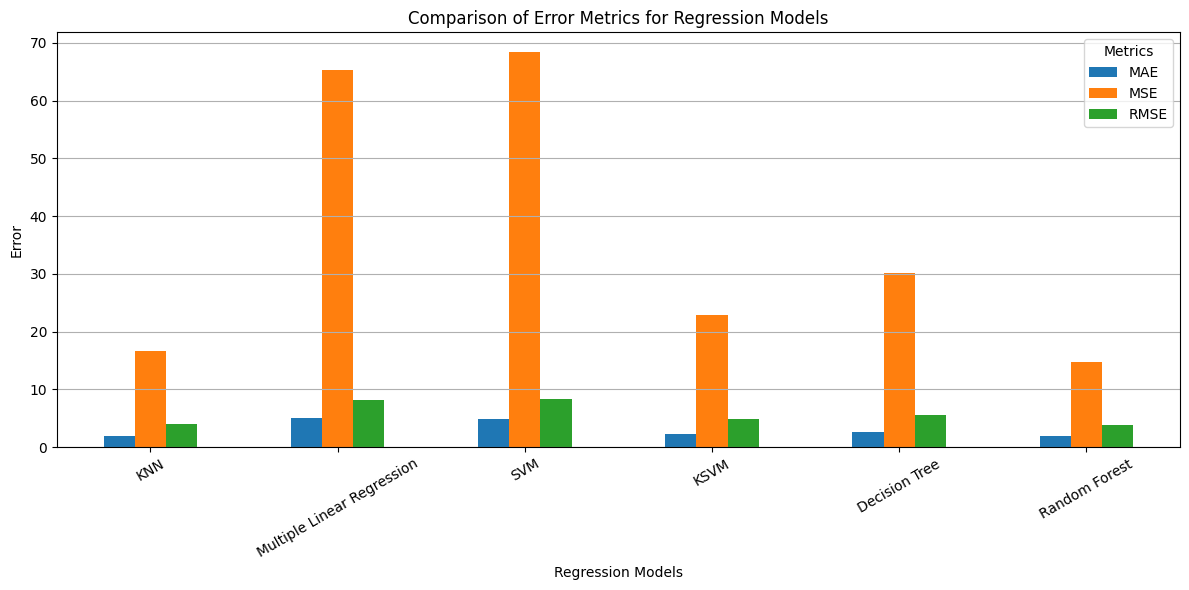

In [ ]:
# Error metrics comparison
error_metrics = ['MAE', 'MSE', 'RMSE']

regression_comparison[error_metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Comparison of Error Metrics for Regression Models')
plt.xlabel('Regression Models')
plt.ylabel('Error')
plt.xticks(rotation=30)
plt.legend(title='Metrics')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

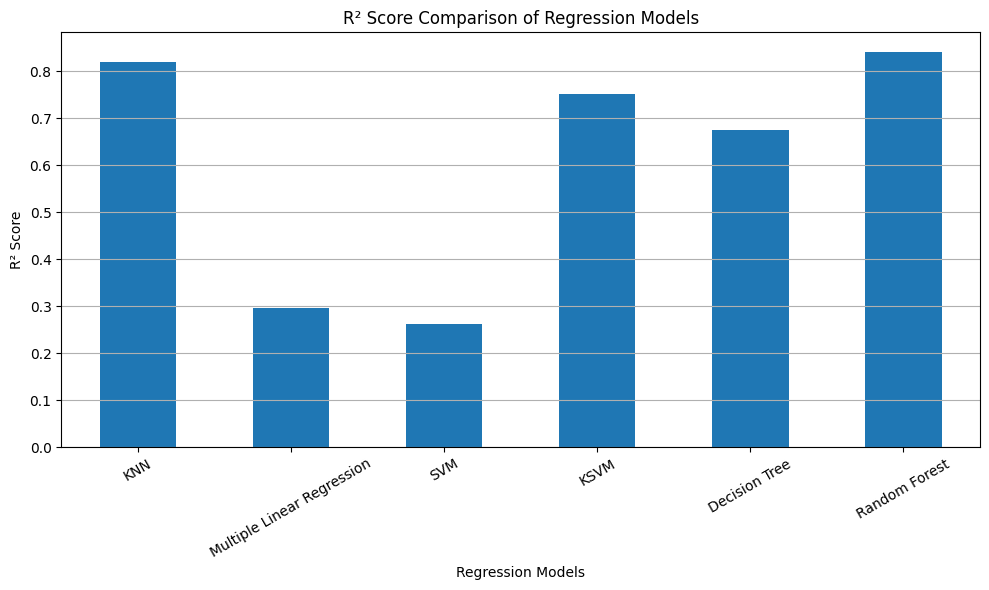

In [ ]:
# R² Score Comparison

regression_comparison['R2 Score'].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('R² Score Comparison of Regression Models')
plt.xlabel('Regression Models')
plt.ylabel('R² Score')
plt.xticks(rotation=30)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Srabani Khuntia, 24BCSB03
# Roll No: 7, Group:E1